In [29]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

In [13]:
df_wine = pd.read_csv('wine_data.csv' , header=None , usecols=[0,1,3])
df_wine.columns = ['Class label' , 'Alcohol' , 'Malic acid']

In [14]:
df_wine.sample(10)

,Class label,Alcohol,Malic acid
54,1,13.74,2.25
30,1,13.73,2.70
154,3,12.58,2.10
26,1,13.39,2.62
39,1,14.22,2.51
59,2,12.37,1.36
32,1,13.68,2.36
43,1,13.24,2.29
74,2,11.96,2.30
101,2,12.60,1.90


In [15]:
df_wine.columns

Index(['Class label', 'Alcohol', 'Malic acid'], dtype='object')

In [16]:
df_wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Class label  178 non-null    int64  
 1   Alcohol      178 non-null    float64
 2   Malic acid   178 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 4.3 KB


In [17]:
df_wine.describe()

,Class label,Alcohol,Malic acid
count,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.366517
std,0.775035,0.811827,0.274344
min,1.000000,11.030000,1.360000
25%,1.000000,12.362500,2.210000
50%,2.000000,13.050000,2.360000
75%,3.000000,13.677500,2.557500
max,3.000000,14.830000,3.230000


<Axes: xlabel='Alcohol', ylabel='Density'>

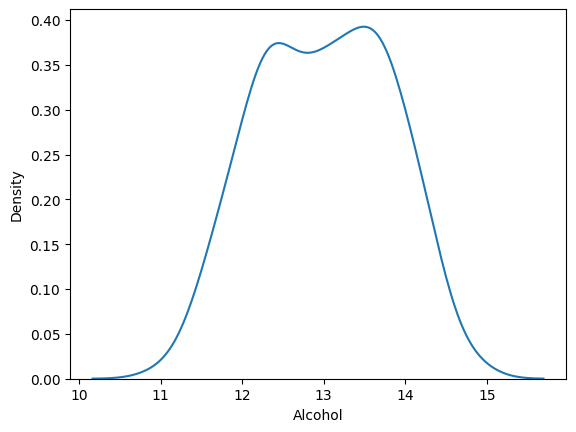

In [18]:
sns.kdeplot(df_wine['Alcohol'])

<Axes: xlabel='Malic acid', ylabel='Density'>

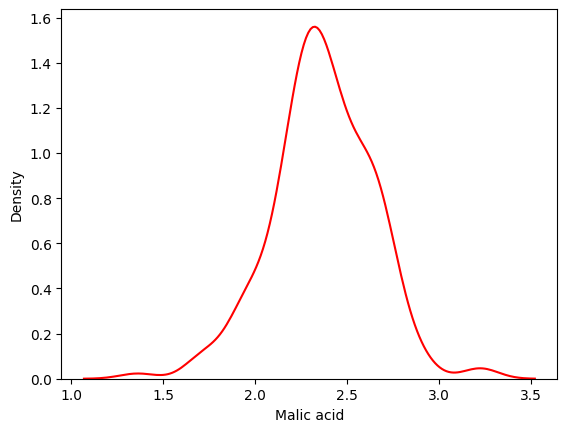

In [20]:
sns.kdeplot(df_wine['Malic acid'] , color='red')

<Axes: xlabel='Alcohol', ylabel='Malic acid'>

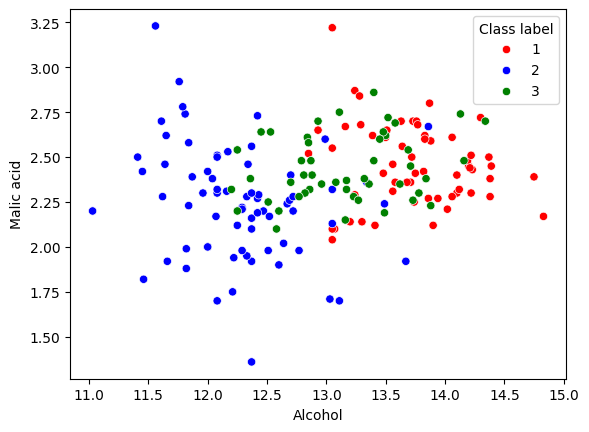

In [28]:
color_d = {1:'red' , 2:'blue' , 3:'green' }

sns.scatterplot( x=df_wine['Alcohol'] , y=df_wine['Malic acid'] ,hue=df_wine['Class label'] ,palette=color_d)

In [30]:
x_train , x_test , y_train , y_test = train_test_split(df_wine.drop(['Class label'] , axis=1) , df_wine['Class label'] , test_size=0.3, random_state=0 )

print(f" X Train : {x_train.shape}")
print(f" X Test : {x_test.shape}")

 X Train : (124, 2)
 X Test : (54, 2)


In [42]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaler.fit(x_train)

x_train_scaler = scaler.transform(x_train)
x_test_scaler = scaler.transform(x_test)

In [43]:
print("Data shape:", np.shape(x_test_scaler))

Data shape: (54, 2)


In [44]:
x_train_scaler

array([[0.72043011, 0.53763441],
       [0.31989247, 0.31182796],
       [0.60215054, 0.48387097],
       [0.57258065, 0.42473118],
       [0.76075269, 0.70430108],
       [0.48924731, 0.65591398],
       [0.75537634, 0.5483871 ],
       [0.61021505, 0.41935484],
       [0.54301075, 0.51612903],
       [0.39784946, 0.47849462],
       [0.33870968, 0.33333333],
       [0.46774194, 0.33333333],
       [0.5188172 , 0.53225806],
       [0.70967742, 0.30107527],
       [0.57258065, 0.70430108],
       [0.36021505, 0.        ],
       [0.38709677, 0.4516129 ],
       [0.20967742, 0.74193548],
       [0.59408602, 0.5       ],
       [0.82526882, 0.50537634],
       [0.15591398, 0.72043011],
       [0.52688172, 0.66666667],
       [0.46774194, 0.49462366],
       [0.65860215, 0.68817204],
       [0.1155914 , 0.24731183],
       [0.27956989, 0.43548387],
       [0.21236559, 0.33870968],
       [0.65053763, 0.66666667],
       [0.31451613, 0.51612903],
       [0.54301075, 0.3655914 ],
       [0.

In [45]:
# Numpy to data frame

x_train_scaler = pd.DataFrame(x_train_scaler, columns=x_train.columns)
X_test_scaled = pd.DataFrame(x_test_scaler, columns=x_test.columns)

In [52]:
np.round(x_train.describe() ,1 )

,Alcohol,Malic acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,0.3
min,11.0,1.4
25%,12.4,2.2
50%,13.0,2.4
75%,13.6,2.6
max,14.8,3.2


In [51]:
np.round(x_train_scaler.describe(),1)

,Alcohol,Malic acid
count,124.0,124.0
mean,0.5,0.5
std,0.2,0.1
min,0.0,0.0
25%,0.4,0.5
50%,0.5,0.5
75%,0.7,0.6
max,1.0,1.0


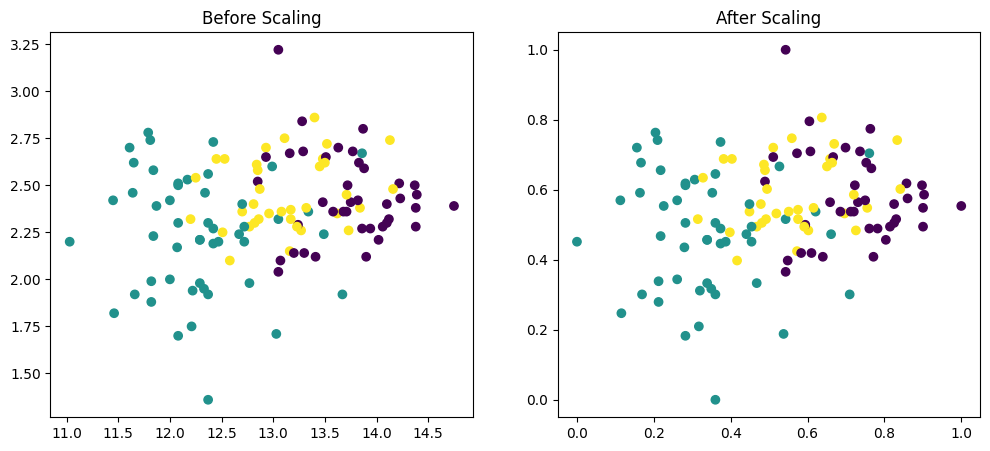

In [53]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(x_train['Alcohol'], x_train['Malic acid'],c=y_train)
ax1.set_title("Before Scaling")
ax2.scatter(x_train_scaler['Alcohol'], x_train_scaler['Malic acid'],c=y_train)
ax2.set_title("After Scaling")
plt.show()

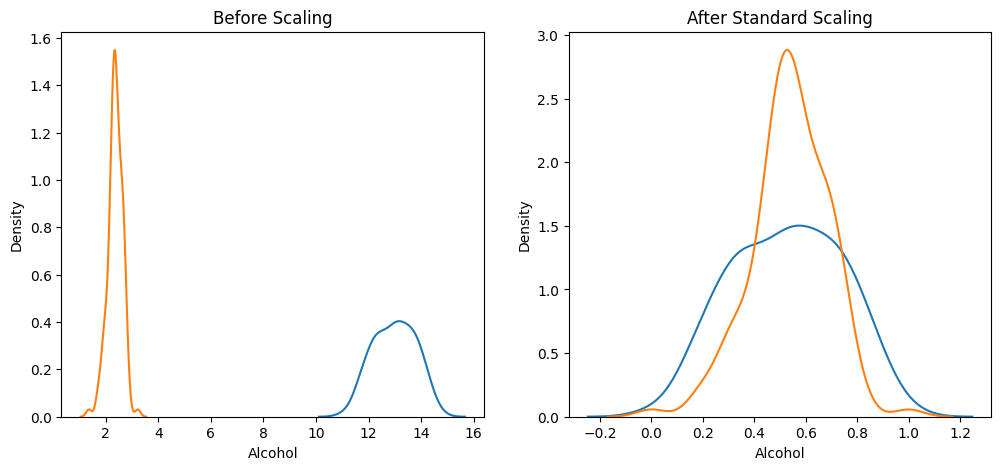

In [54]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(x_train['Alcohol'], ax=ax1)
sns.kdeplot(x_train['Malic acid'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(x_train_scaler['Alcohol'], ax=ax2)
sns.kdeplot(x_train_scaler['Malic acid'], ax=ax2)
plt.show()

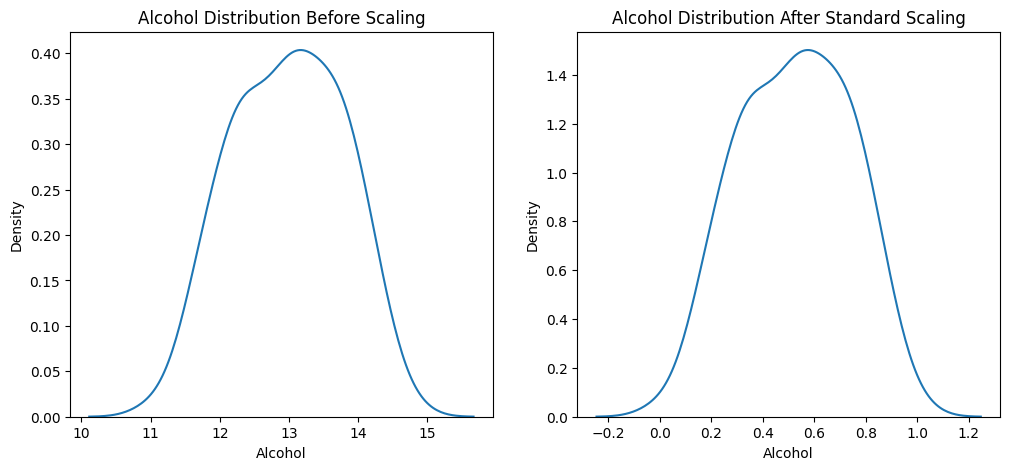

In [55]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Alcohol Distribution Before Scaling')
sns.kdeplot(x_train['Alcohol'], ax=ax1)

# after scaling
ax2.set_title('Alcohol Distribution After Standard Scaling')
sns.kdeplot(x_train_scaler['Alcohol'], ax=ax2)
plt.show()

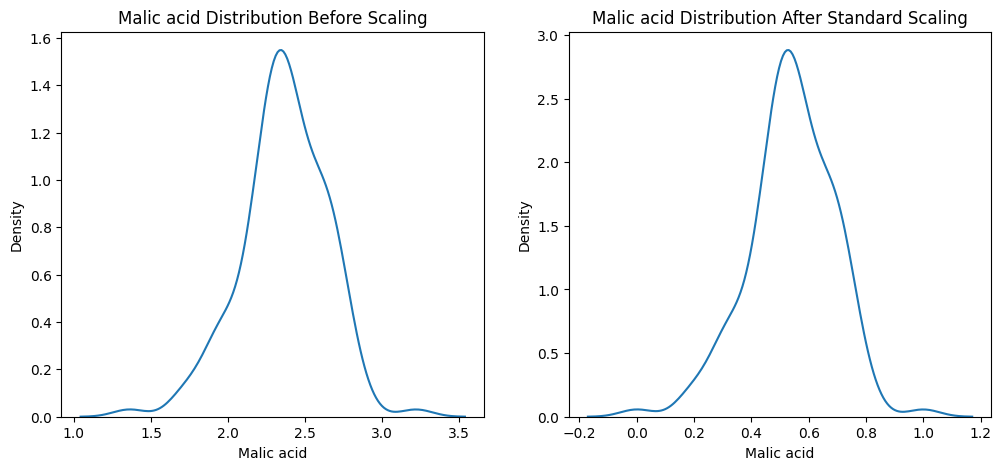

In [56]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Malic acid Distribution Before Scaling')
sns.kdeplot(x_train['Malic acid'], ax=ax1)

# after scaling
ax2.set_title('Malic acid Distribution After Standard Scaling')
sns.kdeplot(x_train_scaler['Malic acid'], ax=ax2)
plt.show()